Dataset shape: (1036, 24)

First 5 records:
   laureateId         knownName  gender   birthDate birthCountry  \
0        1065    Henri B. Kagan    male  1930-12-15       France   
1        1066        Kenso Soai    male  1950-00-00        Japan   
2        1070  Michael Woodford    male  1955-00-00          USA   
3        1069    Robert E. Hall    male  1943-00-00          USA   
4        1067       Anne Carson  female  1950-06-21       Canada   

  birthContinent  awardYear           category portion  prizeAmount  ...  \
0         Europe       2026          Chemistry     1/2     12000000  ...   
1           Asia       2026          Chemistry     1/2     12000000  ...   
2  North America       2026  Economic Sciences     1/2     12000000  ...   
3  North America       2026  Economic Sciences     1/2     12000000  ...   
4  North America       2026         Literature       1     12000000  ...   

   affiliationCountry isOrganization ageAtAward  \
0              France          False   

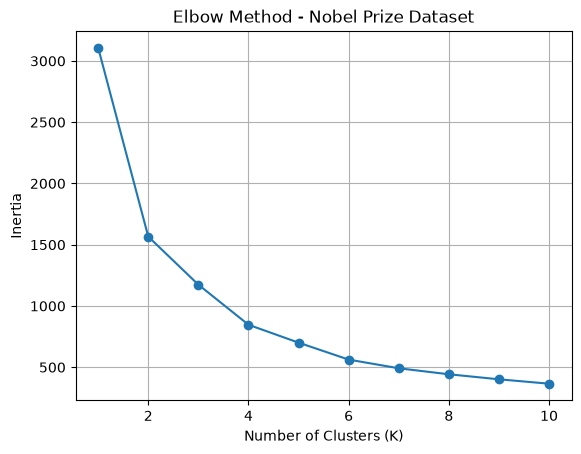


First 10 cluster assignments:
          knownName  ageAtAward  awardYear  prizeAmountAdjusted  Cluster
0    Henri B. Kagan          96       2026             12000000        0
1        Kenso Soai          76       2026             12000000        0
2  Michael Woodford          71       2026             12000000        0
3    Robert E. Hall          83       2026             12000000        0
4       Anne Carson          76       2026             12000000        0
5       Navi Pillay          85       2026             12000000        0
6    Francis Halzen          82       2026             12000000        0
7       Georg Nagel          73       2026             12000000        0
8   Karl Deisseroth          55       2026             12000000        0
9    Peter Hegemann          72       2026             12000000        0


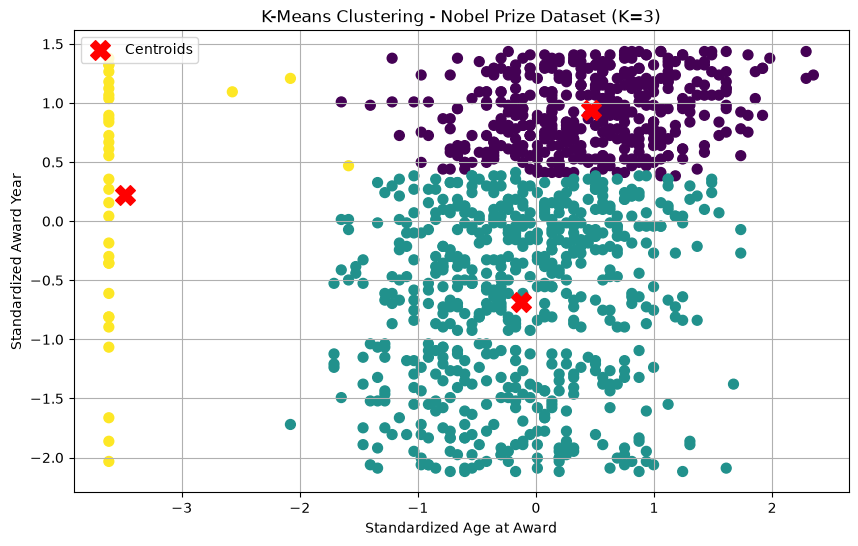


Cluster Statistics:
         ageAtAward    awardYear  prizeAmountAdjusted
Cluster                                              
0         66.333333  2008.467626         1.235469e+07
1         56.721368  1951.550427         5.000765e+06
2          2.205882  1983.264706         8.674278e+06

Clustered dataset saved successfully!


In [3]:

# K-MEANS CLUSTERING ON NOBEL PRIZE DATASET

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 2: Load the dataset
df = pd.read_csv("nobel_prize_laureates_1901_2026.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

# Step 3: Select numerical features
X = df[
    ["ageAtAward", "awardYear", "prizeAmountAdjusted"]
].copy()

# Handle missing values
X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna()

print("\nSelected data shape:", X.shape)

# Step 4: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Apply the Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Step 6: Plot the Elbow graph
plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Nobel Prize Dataset")

plt.grid(True)
plt.show()

# Step 7: Apply K-Means with K = 3
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

# Step 8: Add cluster assignments to the dataset
df_result = df.loc[X.index].copy()
df_result["Cluster"] = clusters

print("\nFirst 10 cluster assignments:")
print(df_result[
    ["knownName", "ageAtAward", "awardYear",
     "prizeAmountAdjusted", "Cluster"]
].head(10))

# Step 9: Visualize the clusters
plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel("Standardized Age at Award")
plt.ylabel("Standardized Award Year")

plt.title("K-Means Clustering - Nobel Prize Dataset (K=3)")
plt.legend()
plt.grid(True)
plt.show()

# Step 10: Display cluster statistics
print("\nCluster Statistics:")

print(
    df_result.groupby("Cluster")[
        ["ageAtAward", "awardYear", "prizeAmountAdjusted"]
    ].mean()
)

# Step 11: Save the result
df_result.to_csv(
    "nobel_prize_clustered.csv",
    index=False
)

print("\nClustered dataset saved successfully!")
